<a href="https://colab.research.google.com/github/OJB-Quantum/QC-Hardware-How-To/blob/main/Jupyter%20Notebook%20Scripts/High_Value_Quantum_Native_Simulation_Applications_Visualized_in_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

Using Python 3.13.16 environment at: /usr
Checked 2 packages in 79ms


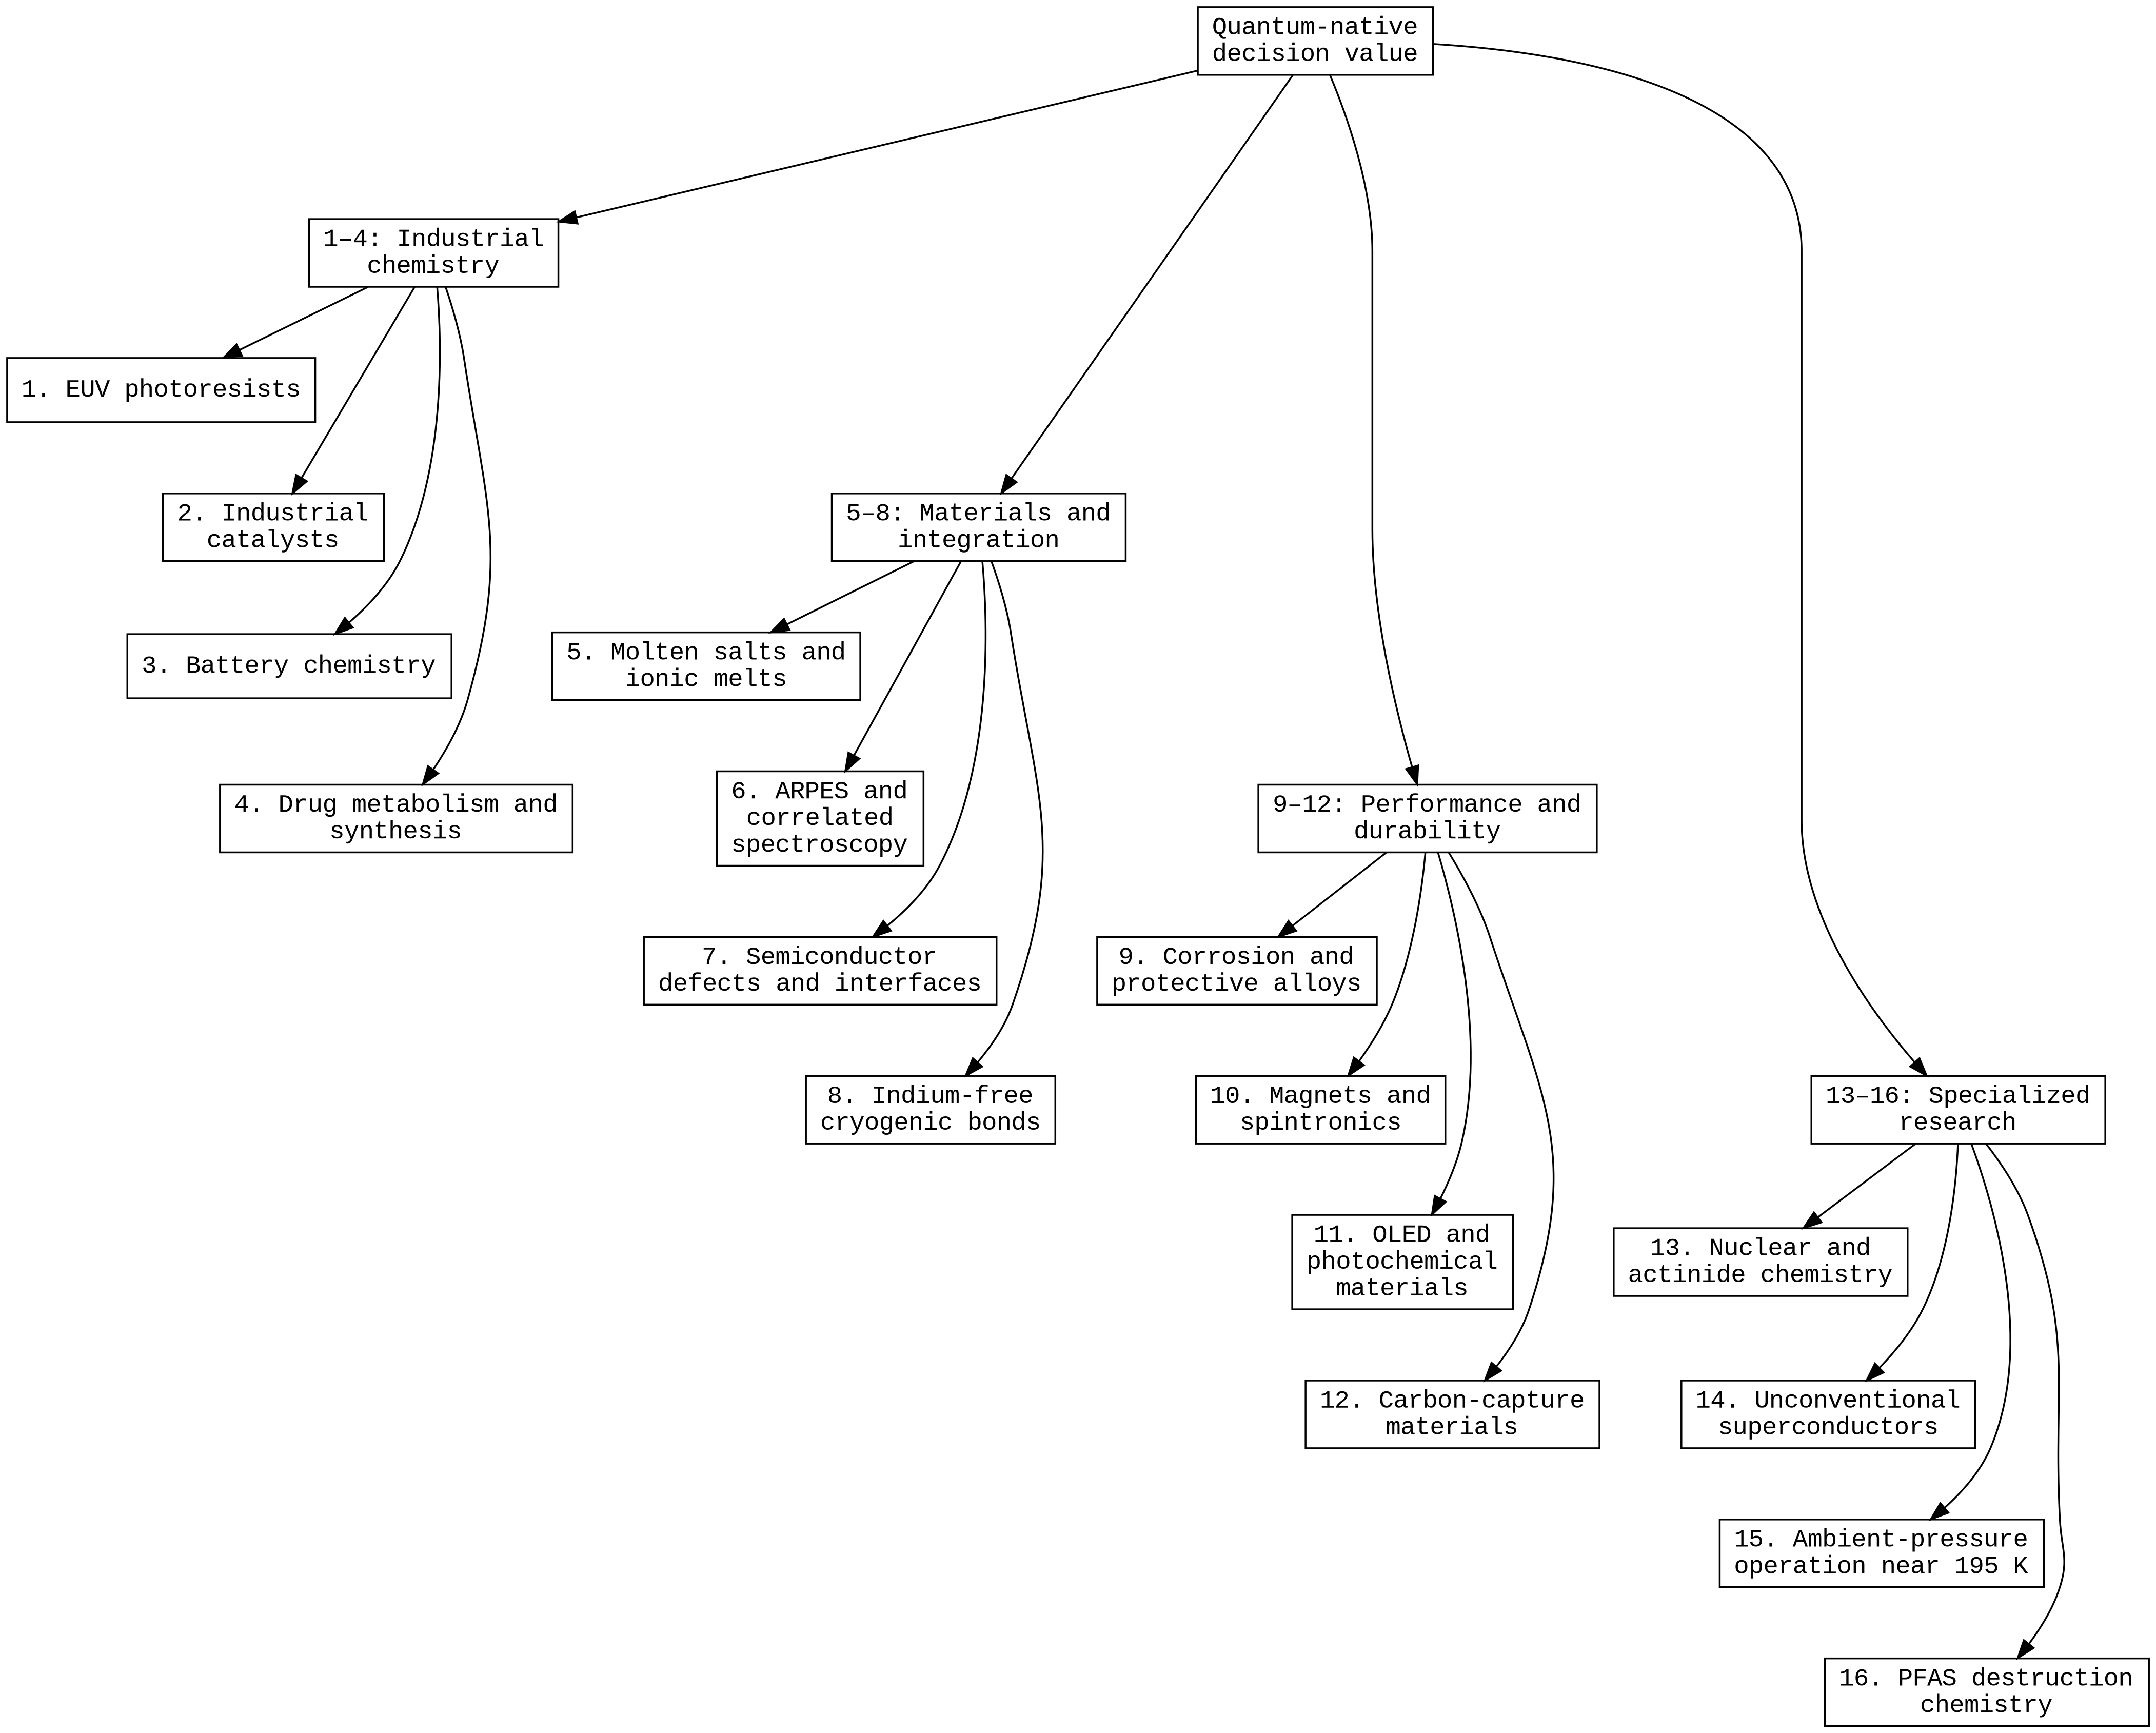

In [9]:
!uv pip install graphviz ipython

"""This script constructs a slightly staggered and stacked quantum-native decision value graph in-memory.

The graph avoids orthogonal edges and maintains an absolute monochrome aesthetic. Control parameters
defined at the top level dictate the font, resolution, and staggered stacking behavior.
"""

import graphviz
from IPython.display import display, Image

# Control Knobs
GRAPH_DPI = "250"
NODE_FONT = "DejaVu Sans"
NODE_FONT_WEIGHT = "normal"
EDGE_ROUTING = "spline"
NODE_SHAPE = "box"
BACKGROUND_COLOR = "white"
FOREGROUND_COLOR = "black"
RANK_DIRECTION = "TB"
MAX_CHARACTERS_PER_LINE = 22
RANK_SEPARATION = "0.55"            # Vertical distance (inches) between consecutive ranks
NODE_SEPARATION = "0.25"            # Horizontal distance (inches) between adjacent nodes
BRANCH_STAGGER_STEP = 2             # Stagger multiplier between primary categories
LEAF_STAGGER_STEP = 1               # Stagger multiplier between leaves within a category
STACK_CATEGORIES_VERTICALLY = False # Allow natural slight staggering instead of a strict single column
STACK_LEAVES_VERTICALLY = True    # Allow natural slight staggering for leaves


def wrap_text(text: str, max_width: int = MAX_CHARACTERS_PER_LINE) -> str:
    """Wraps text to a specified maximum width, hyphenating oversized strings."""
    lines = []
    for paragraph in text.split('\n'):
        current_line = ""
        words = paragraph.split()
        for word in words:
            while len(word) > max_width:
                if current_line:
                    lines.append(current_line)
                    current_line = ""
                chunk = word[:max_width - 1] + "-"
                lines.append(chunk)
                word = word[max_width - 1:]

            if current_line:
                if len(current_line) + 1 + len(word) <= max_width:
                    current_line += " " + word
                else:
                    lines.append(current_line)
                    current_line = word
            else:
                current_line = word
        if current_line:
            lines.append(current_line)
    return '\n'.join(lines)


def build_decision_value_tree() -> graphviz.Digraph:
    """Constructs the Graphviz object for quantum-native decision values."""
    tree = graphviz.Digraph(format='png')

    tree.attr(
        dpi=GRAPH_DPI,
        splines=EDGE_ROUTING,
        bgcolor=BACKGROUND_COLOR,
        rankdir=RANK_DIRECTION,
        ranksep=RANK_SEPARATION,
        nodesep=NODE_SEPARATION,
        # ratio=TARGET_ASPECT_RATIO  <-- REMOVED
    )
    tree.attr(
        'node',
        shape=NODE_SHAPE,
        style='solid',
        color=FOREGROUND_COLOR,
        fontcolor=FOREGROUND_COLOR,
        fontname=NODE_FONT
    )
    tree.attr(
        'edge',
        color=FOREGROUND_COLOR,
        arrowhead='normal',
        fontname=NODE_FONT,
        fontsize='10'
    )

    tree.node('R', wrap_text('Quantum-native decision value'))

    hierarchy = [
        (
            'A',
            '1–4: Industrial chemistry',
            [
                ('A1', '1. EUV photoresists'),
                ('A2', '2. Industrial catalysts'),
                ('A3', '3. Battery chemistry'),
                ('A4', '4. Drug metabolism and synthesis'),
            ]
        ),
        (
            'B',
            '5–8: Materials and integration',
            [
                ('B1', '5. Molten salts and ionic melts'),
                ('B2', '6. ARPES and correlated spectroscopy'),
                ('B3', '7. Semiconductor defects and interfaces'),
                ('B4', '8. Indium-free cryogenic bonds'),
            ]
        ),
        (
            'C',
            '9–12: Performance and durability',
            [
                ('C1', '9. Corrosion and protective alloys'),
                ('C2', '10. Magnets and spintronics'),
                ('C3', '11. OLED and photochemical materials'),
                ('C4', '12. Carbon-capture materials'),
            ]
        ),
        (
            'D',
            '13–16: Specialized research',
            [
                ('D1', '13. Nuclear and actinide chemistry'),
                ('D2', '14. Unconventional superconductors'),
                ('D3', '15. Ambient-pressure operation near 195 K'),
                ('D4', '16. PFAS destruction chemistry'),
            ]
        ),
    ]

    previous_terminal_leaf = None

    for b_idx, (branch_id, branch_label, leaves) in enumerate(hierarchy):
        tree.node(branch_id, wrap_text(branch_label))

        # Staggered branch distance from Root
        branch_minlen = str((b_idx + 1) * BRANCH_STAGGER_STEP)
        tree.edge('R', branch_id, minlen=branch_minlen)

        if STACK_CATEGORIES_VERTICALLY and previous_terminal_leaf is not None:
            tree.edge(previous_terminal_leaf, branch_id, style='invis', minlen='1')

        for l_idx, (leaf_id, leaf_label) in enumerate(leaves):
            tree.node(leaf_id, wrap_text(leaf_label))
            leaf_minlen = str((l_idx + 1) * LEAF_STAGGER_STEP)
            tree.edge(branch_id, leaf_id, minlen=leaf_minlen)

            if STACK_LEAVES_VERTICALLY and l_idx > 0:
                prev_leaf_id = leaves[l_idx - 1][0]
                tree.edge(prev_leaf_id, leaf_id, style='invis', minlen=str(LEAF_STAGGER_STEP))

        previous_terminal_leaf = leaves[-1][0]

    return tree


def display_graph(tree: graphviz.Digraph) -> None:
    """Renders the graph in memory and displays the image without HTML wrappers."""
    binary_png = tree.pipe(format='png')
    display(Image(data=binary_png))


if __name__ == '__main__':
    decision_tree = build_decision_value_tree()
    display_graph(decision_tree)

Using Python 3.13.16 environment at: /usr
Checked 2 packages in 113ms


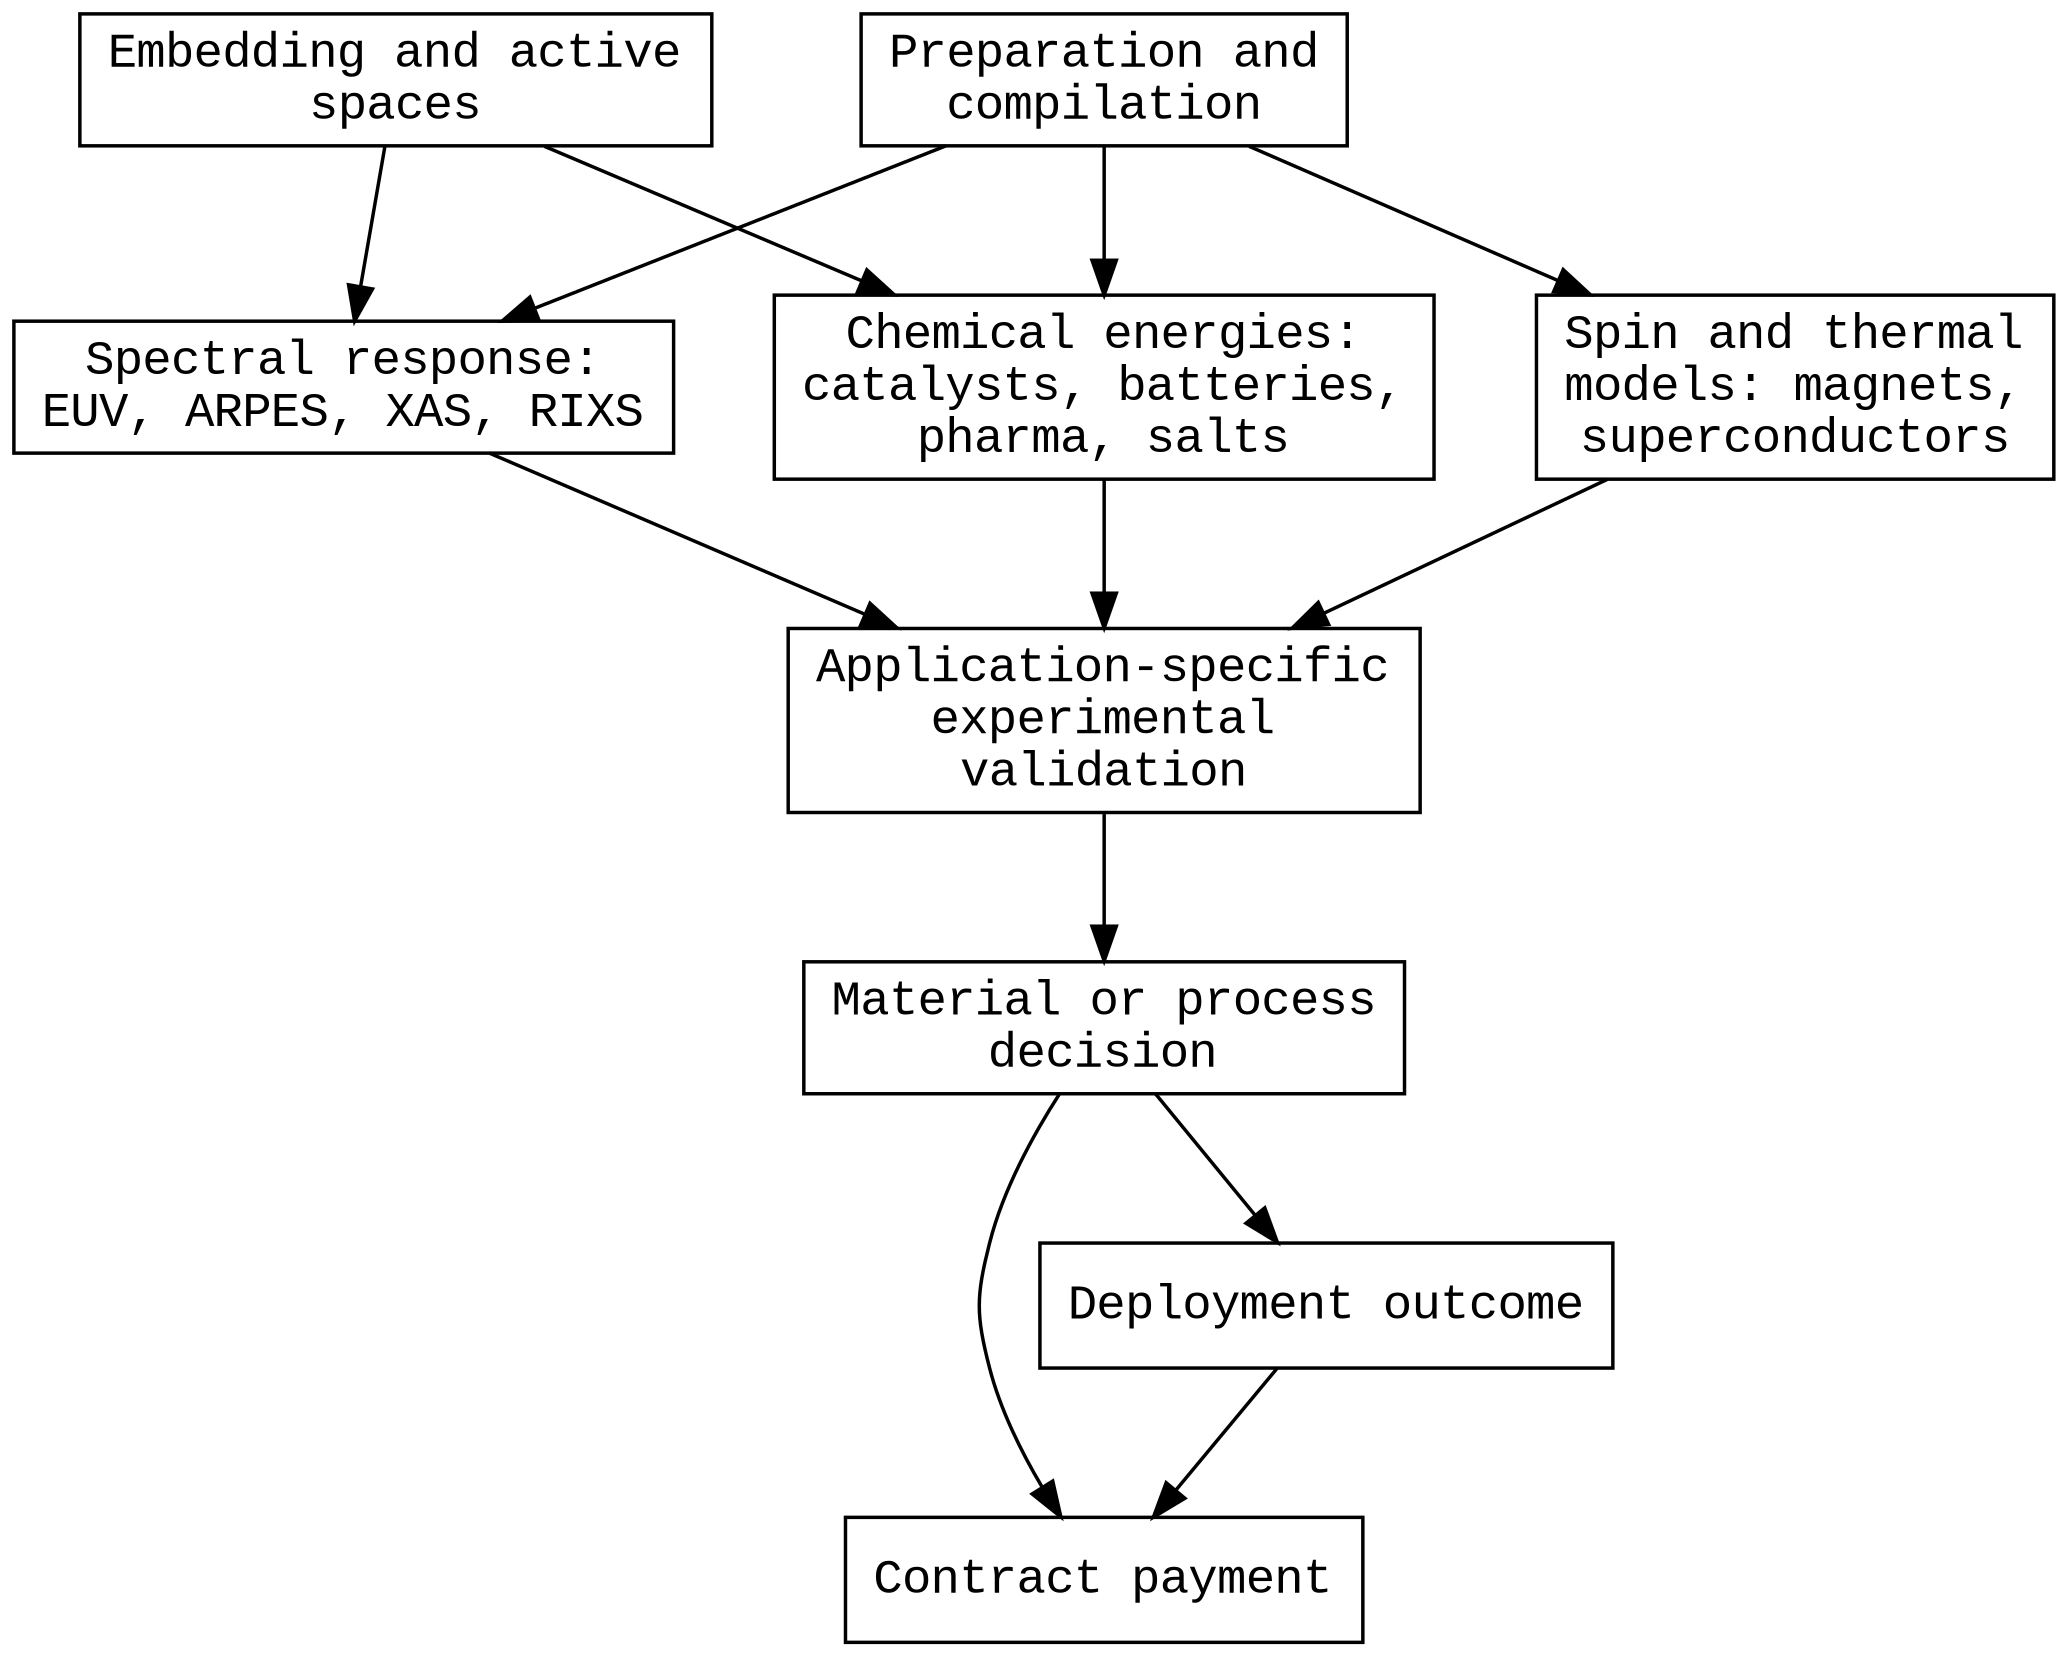

In [10]:
!uv pip install graphviz ipython

"""This script constructs a quantum-native workflow graph.
"""

import graphviz
from IPython.display import display, Image

# Control Knobs
GRAPH_DPI = "250"
NODE_FONT = "DejaVu Sans"
NODE_FONT_WEIGHT = "normal"
EDGE_ROUTING = "spline"
NODE_SHAPE = "box"
BACKGROUND_COLOR = "white"
FOREGROUND_COLOR = "black"
RANK_DIRECTION = "TB"
MAX_CHARACTERS_PER_LINE = 22
RANK_SEPARATION = "0.6"            # Vertical distance between ranks
NODE_SEPARATION = "0.4"            # Horizontal distance between nodes

def wrap_text(text: str, max_width: int = MAX_CHARACTERS_PER_LINE) -> str:
    """Wraps text to a specified maximum width, hyphenating oversized strings."""
    lines = []
    for paragraph in text.split('\n'):
        current_line = ""
        words = paragraph.split()
        for word in words:
            while len(word) > max_width:
                if current_line:
                    lines.append(current_line)
                    current_line = ""
                chunk = word[:max_width - 1] + "-"
                lines.append(chunk)
                word = word[max_width - 1:]

            if current_line:
                if len(current_line) + 1 + len(word) <= max_width:
                    current_line += " " + word
                else:
                    lines.append(current_line)
                    current_line = word
            else:
                current_line = word
        if current_line:
            lines.append(current_line)
    return '\n'.join(lines)


def build_workflow_graph() -> graphviz.Digraph:
    """Constructs the Graphviz object for the quantum-native workflow."""
    tree = graphviz.Digraph(format='png')

    # Global Graph Attributes
    tree.attr(
        dpi=GRAPH_DPI,
        splines=EDGE_ROUTING,
        bgcolor=BACKGROUND_COLOR,
        rankdir=RANK_DIRECTION,
        ranksep=RANK_SEPARATION,
        nodesep=NODE_SEPARATION
    )

    # Node Attributes
    tree.attr(
        'node',
        shape=NODE_SHAPE,
        style='solid',
        color=FOREGROUND_COLOR,
        fontcolor=FOREGROUND_COLOR,
        fontname=NODE_FONT
    )

    # Edge Attributes
    tree.attr(
        'edge',
        color=FOREGROUND_COLOR,
        arrowhead='normal',
        fontname=NODE_FONT,
        fontsize='10'
    )

    # Define Nodes (with wrapped text)
    nodes = {
        'E': 'Embedding and active spaces',
        'P': 'Preparation and compilation',
        'C': 'Chemical energies: catalysts, batteries, pharma, salts',
        'S': 'Spectral response: EUV, ARPES, XAS, RIXS',
        'M': 'Spin and thermal models: magnets, superconductors',
        'V': 'Application-specific experimental validation',
        'D': 'Material or process decision',
        'O': 'Deployment outcome',
        'F': 'Contract payment'
    }

    for node_id, label in nodes.items():
        tree.node(node_id, wrap_text(label))

    # Define Edges (following the Mermaid logic)
    edges = [
        ('E', 'C'),
        ('E', 'S'),
        ('P', 'C'),
        ('P', 'S'),
        ('P', 'M'),
        ('C', 'V'),
        ('S', 'V'),
        ('M', 'V'),
        ('V', 'D'),
        ('D', 'O'),
        ('D', 'F'),
        ('O', 'F'),
    ]

    for start, end in edges:
        tree.edge(start, end)

    return tree


def display_graph(tree: graphviz.Digraph) -> None:
    """Renders the graph in memory and displays the image."""
    binary_png = tree.pipe(format='png')
    display(Image(data=binary_png))


if __name__ == '__main__':
    workflow_graph = build_workflow_graph()
    display_graph(workflow_graph)